# CNN para extraer la vibración del puente desde un carro (drive-by)

**Objetivo:** entrenar una red neuronal convolucional (CNN) que reciba la aceleración medida dentro de un carro que cruza un puente y devuelva solo la vibración del puente, sin la rugosidad de la carretera, la dinámica del carro ni el ruido del teléfono. Con esa vibración se buscan las propiedades dinámicas del puente: las frecuencias de todos sus modos (f1, f2, f3, …).

**Idea:** la red recibe solo lo que mide el teléfono y una máscara que le dice dónde está el puente. No recibe el perfil de la carretera, porque en un caso real no se conoce con exactitud. Antes y después del puente la señal solo tiene carretera, carro y ruido; con esos tramos la red puede aprender cómo se ven, y sobre el puente separar lo que viene del puente.

**Datos:** paquete `datasets/p02-five-bridges-traffic` (5 puentes para entrenar, validar y probar; 5 puentes no vistos para generalización).

## Índice

1. Librerías y configuración
2. Cargar los datos
3. Mirar un viaje
4. Preparar la entrada y la salida de la red
5. Dividir en entrenamiento, validación y prueba
6. Construir la red
7. Entrenar la red
8. Evaluar en los viajes de prueba
9. Comparar con un método sin red
10. Probar en puentes no vistos
11. Conclusiones


## 1. Librerías y configuración

Se cargan las librerías que usa el notebook:

- `numpy`: operaciones con arreglos de números (las señales son arreglos).
- `h5py`: leer los archivos de datos `.h5`.
- `matplotlib`: hacer gráficas.
- `torch` (PyTorch): construir y entrenar la red neuronal.

También se fija una **semilla** (`SEED`) para que los resultados aleatorios sean siempre los mismos, y se elige el **dispositivo**: la GPU (`cuda`) si está disponible, si no, el procesador (`cpu`).

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch

# Fixed seed so that every run gives the same random numbers
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the GPU if there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2. Cargar los datos

Cada archivo `.h5` guarda muchos viajes. Un **viaje** es un carro que recorre 100 m de carretera, cruza el puente y recorre otros 100 m. En cada viaje hay varias señales, todas medidas cada 0.005 s (200 muestras por segundo).

Se usa la versión `padded`: todos los viajes tienen el mismo largo (11 000 muestras = 55 s). Los viajes más cortos se rellenan con ceros al final.

Cada señal se guarda en una tabla de números: **una fila por viaje y una columna por muestra** (1000 filas × 11 000 columnas).

Se leen las señales que se usan en el notebook (Tabla 1 y Figura 1):

**Tabla 1.** Señales que se leen de cada viaje.

| Variable | Qué es | Uso |
|---|---|---|
| `measured` | aceleración medida por el teléfono dentro del carro [m/s²] | entrada |
| `road_acc` | aceleración que la rugosidad de la carretera le impone a la rueda [m/s²] | solo para mirar (sección 3); no entra a la red |
| `bridge_acc` | aceleración del puente en el punto donde está la rueda [m/s²] | salida que debe predecir la red |
| `segment` | 0 = antes del puente, 1 = sobre el puente, 2 = después | saber dónde está el carro |
| `valid` | 1 = muestra real, 0 = relleno con ceros | no usar el relleno |

Y tres datos de cada viaje (un número por viaje): nombre del puente (`bridge_name`), su frecuencia natural (`f1`, en Hz) y la velocidad del carro (`speed`, en m/s).

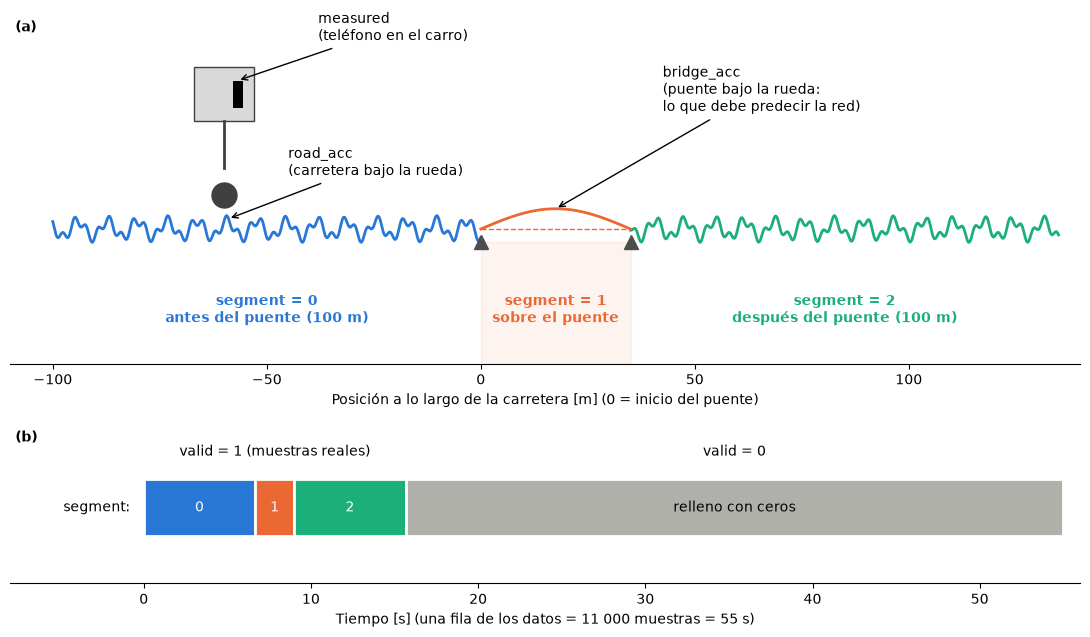

In [2]:
# Diagram only: an illustrative crossing (synthetic numbers), it does not use the data
from matplotlib.patches import Rectangle

BEFORE, BRIDGE, AFTER, PADDING = "#2a78d6", "#eb6834", "#1baf7a", "#b0b0ab"
L = 35.0      # span of the illustrated bridge [m]
v = 15.0      # speed of the illustrated car [m/s]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), height_ratios=[2.2, 1])

# (a) Side view of the crossing, along the road
x_road1 = np.linspace(-100, 0, 400)
x_road2 = np.linspace(L, L + 100, 400)
x_deck = np.linspace(0, L, 200)
rng = np.random.default_rng(SEED)
bumps = lambda x: 0.25 * np.sin(0.9 * x + rng.uniform(0, 6)) + 0.15 * np.sin(2.3 * x)   # fake roughness
ax1.plot(x_road1, bumps(x_road1), color=BEFORE, lw=2)
ax1.plot(x_road2, bumps(x_road2), color=AFTER, lw=2)
ax1.plot(x_deck, 0.6 * np.sin(np.pi * x_deck / L), color=BRIDGE, lw=2)      # deck moving (exaggerated)
ax1.plot(x_deck, np.zeros_like(x_deck), color=BRIDGE, lw=1, ls="--")        # deck at rest
ax1.plot([0, L], [-0.4, -0.4], "^", color="0.3", ms=10)                      # supports
ax1.fill_between([0, L], -4, -0.4, color=BRIDGE, alpha=0.08)

# Quarter car on the road before the bridge: wheel, spring and body with the phone
xc = -60
ax1.plot(xc, 1.0, "o", ms=18, color="0.25")
ax1.plot([xc, xc], [1.8, 3.2], color="0.25", lw=2)
ax1.add_patch(Rectangle((xc - 7, 3.2), 14, 1.6, fc="0.85", ec="0.25"))
ax1.add_patch(Rectangle((xc + 2, 3.6), 2.5, 0.8, fc="black"))

ax1.annotate("measured\n(teléfono en el carro)", (xc + 3.2, 4.4), (xc + 22, 5.6), arrowprops=dict(arrowstyle="->"))
ax1.annotate("road_acc\n(carretera bajo la rueda)", (xc + 1, 0.3), (-45, 1.6),
             arrowprops=dict(arrowstyle="->"))
ax1.annotate("bridge_acc\n(puente bajo la rueda:\nlo que debe predecir la red)", (L / 2, 0.6), (L / 2 + 25, 3.5),
             arrowprops=dict(arrowstyle="->"))

# Segment of each part of the road
for x0, x1, color, text in [(-100, 0, BEFORE, "segment = 0\nantes del puente (100 m)"),
                            (0, L, BRIDGE, "segment = 1\nsobre el puente"),
                            (L, L + 100, AFTER, "segment = 2\ndespués del puente (100 m)")]:
    ax1.text((x0 + x1) / 2, -2.4, text, ha="center", va="center", color=color, fontweight="bold")
ax1.set_xlim(-110, L + 105)
ax1.set_ylim(-4, 6.5)
ax1.set_yticks([])
ax1.set_xlabel("Posición a lo largo de la carretera [m] (0 = inicio del puente)")
ax1.text(0.005, 0.97, "(a)", transform=ax1.transAxes, va="top", fontweight="bold")

# (b) One row of the data: the same crossing along time, padded with zeros up to 55 s
t_before, t_bridge, t_after = 100 / v, L / v, 100 / v
starts = [0, t_before, t_before + t_bridge, t_before + t_bridge + t_after]
parts = [(starts[0], starts[1], BEFORE, "0"), (starts[1], starts[2], BRIDGE, "1"),
         (starts[2], starts[3], AFTER, "2"), (starts[3], 55, PADDING, "relleno con ceros")]
for t0, t1, color, text in parts:
    ax2.barh(0, t1 - t0, left=t0, color=color, height=0.6, edgecolor="white", linewidth=2)
    ax2.text((t0 + t1) / 2, 0, text, ha="center", va="center", color="white" if text != "relleno con ceros" else "black")
ax2.text(starts[3] / 2, 0.55, "valid = 1 (muestras reales)", ha="center")
ax2.text((starts[3] + 55) / 2, 0.55, "valid = 0", ha="center")
ax2.text(-0.8, 0, "segment:", ha="right", va="center")
ax2.set_xlim(-8, 56)
ax2.set_ylim(-0.8, 0.9)
ax2.set_yticks([])
ax2.set_xlabel("Tiempo [s] (una fila de los datos = 11 000 muestras = 55 s)")
ax2.text(0.005, 0.95, "(b)", transform=ax2.transAxes, va="top", fontweight="bold")

for ax in (ax1, ax2):
    ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

**Figura 1.** Qué es cada dato de un viaje (esquema ilustrativo, no son datos reales; el movimiento del puente está exagerado). (a) Vista lateral del recorrido: el teléfono mide `measured` dentro del carro; `road_acc` es lo que la carretera le impone a la rueda (no entra a la red); `bridge_acc` es el movimiento del puente bajo la rueda, que es lo que debe predecir la red. (b) El mismo viaje como una fila de los datos: las muestras reales (`valid` = 1) con su `segment`, y después el relleno con ceros (`valid` = 0) hasta 55 s.

Notas sobre el código:

- `[:]` significa "leer todo".
- `road_acc` y `bridge_acc` se guardan en el archivo con una dimensión extra para el número de ejes del carro. Aquí el carro tiene un solo eje, así que `[:, 0, :]` toma todos los viajes, el eje 0 (el único) y todas las muestras.
- `.astype(str)` convierte los nombres de los puentes a texto.

In [3]:
DATA_DIR = Path("datasets/p02-five-bridges-traffic/data")
FS = 200  # samples per second

file = h5py.File(DATA_DIR / "main_padded.h5", "r")

# Signals: one row per crossing, one column per sample
measured = file["measured"][:]                              # car acceleration [m/s^2]
road_acc = file["profile/road_acceleration"][:, 0, :]       # road input to the wheel [m/s^2]
bridge_acc = file["profile/bridge_acceleration"][:, 0, :]   # bridge under the wheel [m/s^2]
segment = file["segment"][:]                                # 0 before, 1 on, 2 after the bridge
valid = file["valid_mask"][:]                               # 1 real sample, 0 padding

# Information of each crossing: one value per crossing
bridge_name = file["metadata/bridge_name"][:].astype(str)
f1 = file["metadata/f1"][:]          # first natural frequency of the bridge [Hz]
bridge_freqs = file["metadata/bridge_frequencies"][:]   # frequencies of all the modes [Hz] (nan = mode not used)
speed = file["metadata/speed"][:]    # car speed [m/s]

file.close()

In [4]:
n_crossings, n_samples = measured.shape
print(f"Crossings: {n_crossings}")
print(f"Samples per crossing: {n_samples} ({n_samples / FS:.0f} s)")
print()

# How many crossings each bridge has, its f1 and the mean speed of the car
for name in np.unique(bridge_name):
    rows = bridge_name == name
    print(f"{name}: {rows.sum()} crossings, f1 = {f1[rows][0]:.1f} Hz, mean speed = {speed[rows].mean():.1f} m/s")

Crossings: 1000
Samples per crossing: 11000 (55 s)

B1: 200 crossings, f1 = 8.0 Hz, mean speed = 15.1 m/s
B2: 200 crossings, f1 = 4.5 Hz, mean speed = 14.4 m/s
B3: 200 crossings, f1 = 3.0 Hz, mean speed = 14.1 m/s
B4: 200 crossings, f1 = 2.3 Hz, mean speed = 15.2 m/s
B5: 200 crossings, f1 = 1.6 Hz, mean speed = 14.8 m/s


Hay 1000 viajes, 200 por puente. La velocidad media de B3 es un poco más baja porque, en carretera de clase C (más rugosa) y a alta velocidad, la rueda se despega del pavimento; esos viajes se descartaron al generar los datos y se volvieron a sortear.

## 3. Mirar un viaje

Se grafican las tres señales de un viaje en el tiempo: lo que mide el teléfono (`measured`), lo que la carretera le impone a la rueda (`road_acc`) y el movimiento del puente bajo la rueda (`bridge_acc`). Solo se grafican las muestras reales (`valid` = 1), sin el relleno.

El número del viaje se elige con `i`. Se puede cambiar para ver otro viaje.

Crossing 6: bridge B3, f1 = 3.0 Hz, speed = 14.0 m/s


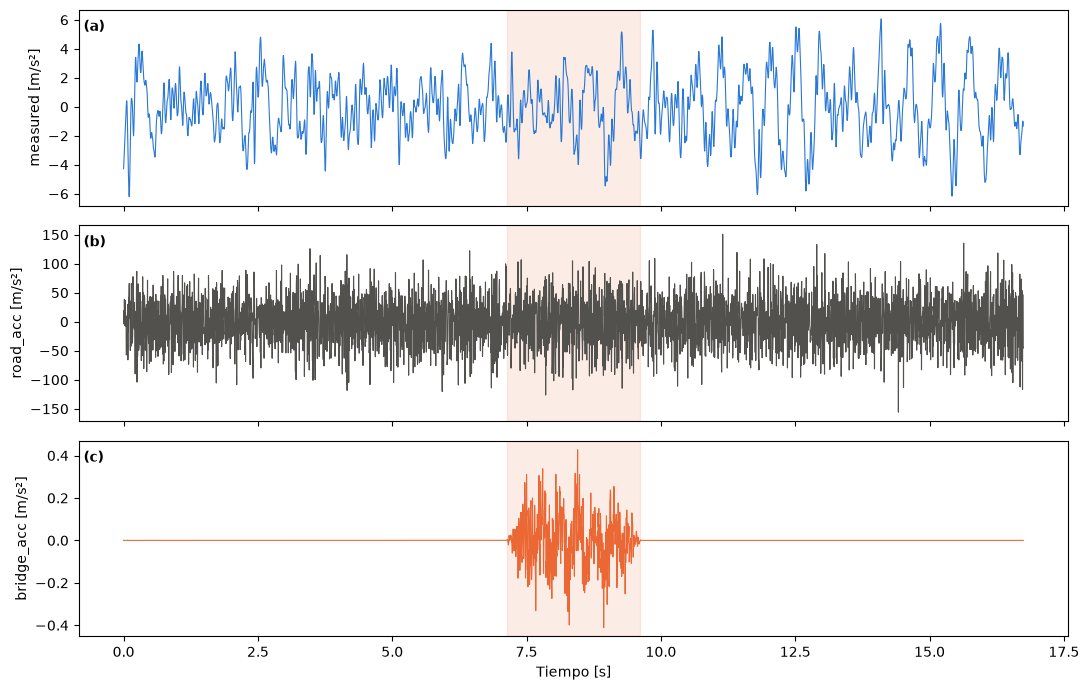

In [5]:
i = 6  # crossing to look at (change the number to see another one)
print(f"Crossing {i}: bridge {bridge_name[i]}, f1 = {f1[i]:.1f} Hz, speed = {speed[i]:.1f} m/s")

t = np.arange(n_samples) / FS        # time of each sample [s]
real = valid[i] == 1                 # real samples, without the padding
on_bridge = segment[i] == 1          # samples on the bridge

# Time when the car enters and leaves the bridge
t_enter = t[on_bridge][0]
t_leave = t[on_bridge][-1]

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
signals = [measured, road_acc, bridge_acc]
names = ["measured [m/s²]", "road_acc [m/s²]", "bridge_acc [m/s²]"]
colors = ["#2a78d6", "#52514e", "#eb6834"]
for ax, signal, name, color, letter in zip(axes, signals, names, colors, "abc"):
    ax.plot(t[real], signal[i][real], color=color, lw=0.8)
    ax.axvspan(t_enter, t_leave, color="#eb6834", alpha=0.12)   # time on the bridge
    ax.set_ylabel(name)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 2.** Señales del viaje 6 (puente B3, f1 = 3.0 Hz, 14.0 m/s). (a) Aceleración medida por el teléfono. (b) Aceleración que la carretera le impone a la rueda. (c) Aceleración del puente bajo la rueda (salida de la red). La franja naranja marca el tiempo sobre el puente. Cada panel tiene su propia escala vertical.

Qué se ve:

- **(a) `measured`:** varía entre ±5 m/s² y se ve igual dentro y fuera del puente. A simple vista no se nota el puente.
- **(b) `road_acc`:** es unas 20 veces más grande que lo medido (±100 m/s²) y cambia muy rápido. Esos cambios rápidos casi no llegan al teléfono: el carro los atenúa.
- **(c) `bridge_acc`:** solo existe sobre el puente (fuera vale 0) y es unas 15 veces más pequeño que lo medido (±0.4 m/s²).

Una observación para la sección 4: `bridge_acc` vibra mucho más rápido que f1 = 3 Hz. Además del modo 1 contiene los modos 2 y 3 (12 y 27 Hz). En `bridge_acc`, el modo 1 es solo el 14–38 % de la energía según el puente, pero el carro casi no transmite los modos altos: de lo que llega al teléfono desde el puente, el modo 1 es el 95–99 %.

Para verlo directamente se compara `bridge_acc` con **la parte de la señal del teléfono que viene del puente**. El simulador guarda la señal del teléfono separada por fuente (puente, rugosidad, ruido), así que esa parte se puede leer del archivo. En un caso real no se tiene; aquí solo se usa para mirar, no como entrada de la red.

Se hace un zoom al tiempo sobre el puente (Figura 3).

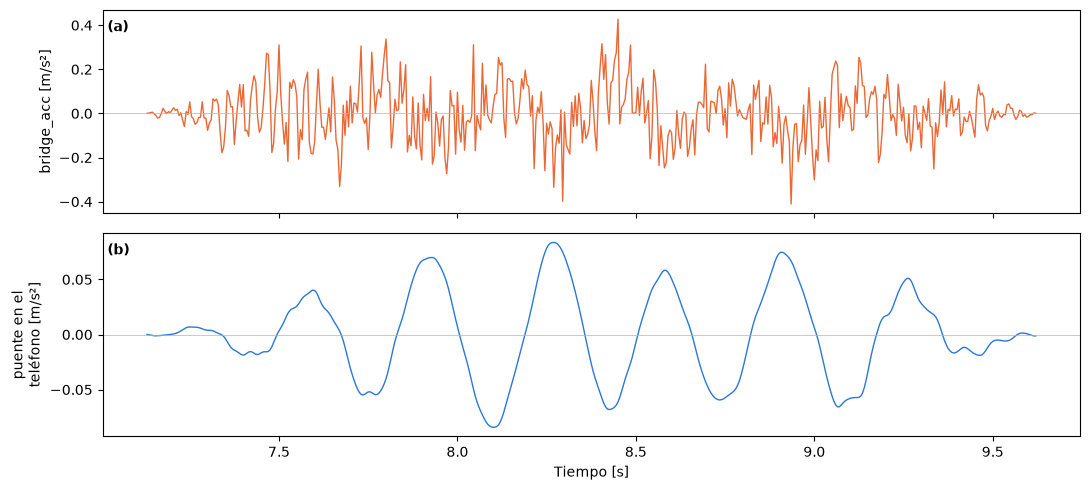

In [6]:
# Part of the phone signal that comes from the bridge (all its modes), only for crossing i
file = h5py.File(DATA_DIR / "main_padded.h5", "r")
bridge_in_phone = (file["components/bridge_mode_1"][i] + file["components/bridge_mode_2"][i]
                   + file["components/bridge_mode_3"][i] + file["components/bridge_higher_modes"][i])
file.close()

# Zoom: only the time on the bridge
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(t[on_bridge], bridge_acc[i][on_bridge], color="#eb6834", lw=1)
axes[0].set_ylabel("bridge_acc [m/s²]")
axes[1].plot(t[on_bridge], bridge_in_phone[on_bridge], color="#2a78d6", lw=1)
axes[1].set_ylabel("puente en el\nteléfono [m/s²]")
axes[1].set_xlabel("Tiempo [s]")
for ax, letter in zip(axes, "ab"):
    ax.axhline(0, color="0.7", lw=0.5)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
plt.tight_layout()
plt.show()

**Figura 3.** Zoom al tiempo sobre el puente del viaje 6 (B3, f1 = 3.0 Hz). (a) Aceleración del puente bajo la rueda (`bridge_acc`). (b) Parte de la señal del teléfono que viene del puente. Cada panel tiene su propia escala vertical.

- **(a)** El puente vibra con una oscilación irregular y rápida: es la suma de sus modos 1, 2 y 3.
- **(b)** Lo que llega al teléfono es una oscilación suave de unos 3 Hz (un ciclo cada ~0.33 s), es decir, casi solo el modo 1. Es además unas 5 veces más pequeña, y aparece y desaparece al entrar y salir del puente.

## 4. Preparar la entrada y la salida de la red

La red recibe varias señales a la vez, como una foto recibe los tres colores (rojo, verde, azul). A cada señal de entrada se le llama **canal**. Aquí la red recibe 2 canales y devuelve 1 (Tabla 2).

**Tabla 2.** Entrada y salida de la red. Todas tienen 11 000 muestras por viaje.

| | Canal | Qué es | Por qué |
|---|---|---|---|
| Entrada | `measured` | lo que mide el teléfono | es la señal de la que se quiere sacar el puente |
| Entrada | `bridge_mask` | 1 sobre el puente, 0 fuera | le dice a la red dónde está el puente |
| Salida | `target` | `bridge_acc`, con todas sus frecuencias | es lo que la red debe devolver |

La red **no recibe el perfil de la carretera** (`road_acc`): en un caso real no se conoce con exactitud, ni antes, ni sobre, ni después del puente. La red tiene que aprender por sí sola a separar la rugosidad.

Las señales tienen tamaños distintos (`measured` ±5 m/s², `bridge_acc` ±0.4 m/s²). Se llevan a una escala parecida en la sección 5, con los datos de entrenamiento.

### 4.1 Entrada

`np.stack` junta los 2 canales en una sola tabla de 3 dimensiones: **viaje × canal × muestra**.

In [7]:
bridge_mask = (segment == 1).astype(np.float32)   # 1 on the bridge, 0 elsewhere

X = np.stack([measured, bridge_mask], axis=1)     # input of the network
print("X:", X.shape, "(crossings, channels, samples)")

X: (1000, 2, 11000) (crossings, channels, samples)


### 4.2 Salida

La salida es `bridge_acc` tal como viene del archivo, con todas sus frecuencias. Fuera del puente ya vale 0; al multiplicarla por la máscara se asegura que solo exista sobre el puente.

En la sección 3 se vio que el carro casi solo deja pasar el modo 1 del puente (Figura 3). Lo que no llega al teléfono no está en la entrada de la red. Por eso se espera que la red:

- recupere bien el modo 1, que es de donde sale f1;
- no recupere los modos altos ni el contenido rápido de `bridge_acc`.

Esto se comprobará en la sección 8, comparando el espectro de la salida de la red con el de `bridge_acc`.

**Prueba pendiente:** si en la primera corrida (sección 8) el error en las frecuencias altas resulta grande, se debe probar la red con datos sin rugosidad, para ver si es capaz de obtener todos los modos del puente.

In [8]:
target = bridge_acc * bridge_mask   # bridge acceleration under the wheel, only on the bridge

Y = target[:, np.newaxis, :]        # output of the network, with one channel
print("Y:", Y.shape, "(crossings, channels, samples)")

Y: (1000, 1, 11000) (crossings, channels, samples)


### 4.3 Ver la entrada y la salida de un viaje

Se grafican los 2 canales de entrada y la salida del mismo viaje de la sección 3 (Figura 4).

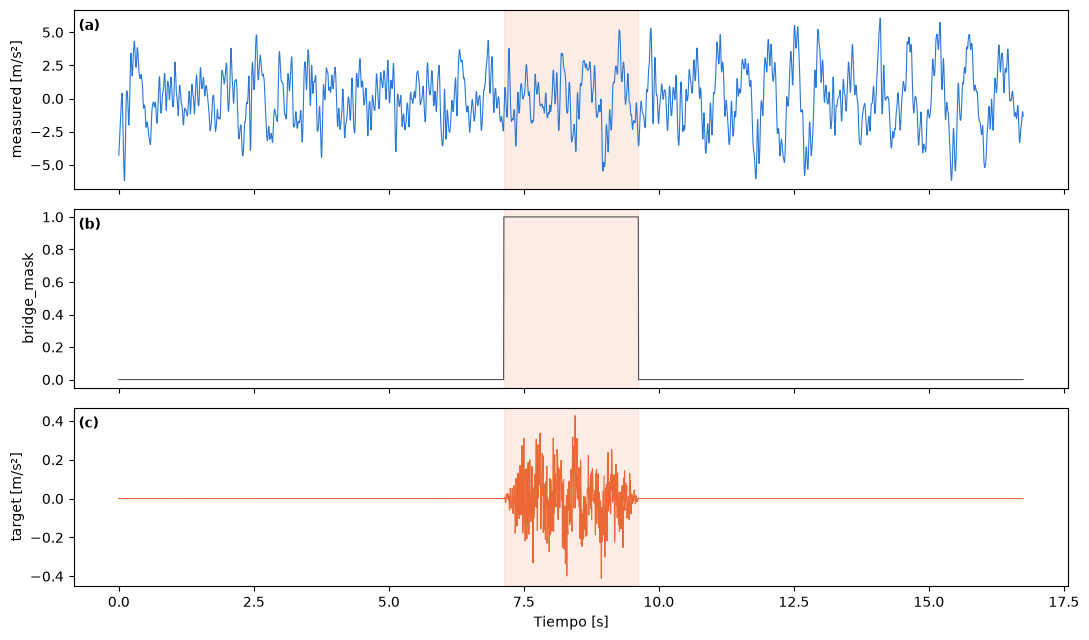

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
signals = [measured, bridge_mask, target]
names = ["measured [m/s²]", "bridge_mask", "target [m/s²]"]
colors = ["#2a78d6", "#52514e", "#eb6834"]
for ax, signal, name, color, letter in zip(axes, signals, names, colors, "abc"):
    ax.plot(t[real], signal[i][real], color=color, lw=0.8)
    ax.axvspan(t_enter, t_leave, color="#eb6834", alpha=0.12)   # time on the bridge
    ax.set_ylabel(name)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 4.** Entrada y salida de la red para el viaje 6 (B3, f1 = 3.0 Hz). (a)–(b) Canales de entrada: aceleración medida y máscara del puente. (c) Salida: aceleración del puente bajo la rueda (`target`). La franja naranja marca el tiempo sobre el puente. Cada panel tiene su propia escala vertical.

Qué se ve:

- **(a):** la red solo recibe lo que mide el teléfono. Fuera del puente esa señal tiene carretera, carro y ruido, pero no puente. Con esos tramos la red puede aprender cómo se ve la señal sin puente.
- **(b):** la máscara le dice a la red dónde está el puente: ahí tiene que separar lo que viene del puente.
- **(c):** la salida es la misma aceleración del puente de la Figura 2c: solo existe sobre el puente y fuera vale 0.

## 5. Dividir en entrenamiento, validación y prueba

Los viajes se separan en tres grupos, cada uno con un papel distinto:

- **Entrenamiento (70 %):** la red aprende con estos viajes.
- **Validación (15 %):** durante el entrenamiento se revisa cómo le va a la red con estos viajes, que no usa para aprender. Sirve para ver si mejora de verdad o solo memoriza los de entrenamiento, y para decidir cuándo parar.
- **Prueba (15 %):** no se tocan hasta el final (sección 8). Dan la nota final de la red.

La división se hace **por puente**: de los 200 viajes de cada puente, 140 van a entrenamiento, 30 a validación y 30 a prueba. Así los 5 puentes están en los tres grupos. La prueba con puentes que la red nunca vio se hace aparte, con el paquete G1–G5 (sección 10).

### 5.1 Dividir los viajes

Para cada puente se buscan sus viajes (`np.where`), se revuelven al azar (`rng.permutation`, con la semilla fija para que siempre salga igual) y se reparten en orden: los primeros 140 a entrenamiento, los 30 siguientes a validación y el resto a prueba.

In [10]:
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []   # numbers of the crossings of each group

for name in np.unique(bridge_name):
    idx = np.where(bridge_name == name)[0]   # crossings of this bridge
    idx = rng.permutation(idx)               # shuffle them
    n_train = int(0.70 * len(idx))           # 140
    n_val = int(0.15 * len(idx))             # 30
    train_idx += list(idx[:n_train])
    val_idx += list(idx[n_train:n_train + n_val])
    test_idx += list(idx[n_train + n_val:])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

**Tabla 3.** Número de viajes de cada puente en cada grupo y frecuencias de sus modos (f_n = n² · f1, hasta 40 Hz).

In [11]:
print("Bridge  train  val  test  mode frequencies [Hz]")
for name in np.unique(bridge_name):
    n_train = np.sum(bridge_name[train_idx] == name)
    n_val = np.sum(bridge_name[val_idx] == name)
    n_test = np.sum(bridge_name[test_idx] == name)
    freqs = bridge_freqs[bridge_name == name][0]   # the same for all crossings of the bridge
    freqs = freqs[~np.isnan(freqs)]                # keep only the modes that exist
    print(f"{name:6}  {n_train:5}  {n_val:3}  {n_test:4}  {freqs}")
print(f"Total   {len(train_idx):5}  {len(val_idx):3}  {len(test_idx):4}")

Bridge  train  val  test  mode frequencies [Hz]
B1        140   30    30  [ 8. 32.]
B2        140   30    30  [ 4.5 18. ]
B3        140   30    30  [ 3. 12. 27.]
B4        140   30    30  [ 2.3  9.2 20.7 36.8]
B5        140   30    30  [ 1.6  6.4 14.4 25.6 40. ]
Total     700  150   150


Cada puente queda con 140 / 30 / 30 viajes. Ningún viaje está en dos grupos a la vez.

### 5.2 Llevar las señales a una escala parecida

Las señales tienen tamaños distintos: `measured` llega a ±5 m/s² y `bridge_acc` a ±0.4 m/s². Una red aprende mejor cuando todos sus números son de un tamaño parecido, cerca de 1. Si no, la señal grande domina y la pequeña casi no se nota.

Cada señal se divide por su **desviación estándar** $\sigma$, que mide cuánto se aleja la señal de cero en promedio:

$$x_{\text{escalada}} = \frac{x}{\sigma} \tag{1}$$

- $x$: la señal en m/s².
- $\sigma$: su desviación estándar en m/s², calculada **solo con los viajes de entrenamiento**.
- $x_{\text{escalada}}$: la señal sin unidades, que se mueve más o menos entre −5 y 5.

Se usan solo los viajes de entrenamiento para que la red no reciba ninguna información de los viajes de validación y prueba. Cada $\sigma$ se calcula con las muestras donde la señal existe:

- `measured`: todas las muestras reales (sin el relleno).
- `target`: las muestras sobre el puente (fuera vale 0).
- `bridge_mask` no se escala: ya vale 0 o 1.

In [12]:
# Samples of the training crossings used to compute each scale
train_real = valid[train_idx] == 1        # real samples (no padding)
train_on_bridge = segment[train_idx] == 1   # samples on the bridge

scale_measured = measured[train_idx][train_real].std()
scale_target = target[train_idx][train_on_bridge].std()

print(f"scale_measured = {scale_measured:.3f} m/s^2")
print(f"scale_target   = {scale_target:.4f} m/s^2")

scale_measured = 0.764 m/s^2
scale_target   = 0.0899 m/s^2


Se divide cada canal por su escala y luego se separan los tres grupos. `scale_target` se guarda: en la sección 8 se usa para pasar la salida de la red de vuelta a m/s².

In [13]:
X_scaled = X.copy()
X_scaled[:, 0, :] = X[:, 0, :] / scale_measured   # measured
# channel 1 (bridge_mask) stays as it is: 0 or 1
Y_scaled = Y / scale_target                       # target

X_train, Y_train = X_scaled[train_idx], Y_scaled[train_idx]
X_val, Y_val = X_scaled[val_idx], Y_scaled[val_idx]
X_test, Y_test = X_scaled[test_idx], Y_scaled[test_idx]

print("Train:", X_train.shape, Y_train.shape)
print("Val:  ", X_val.shape, Y_val.shape)
print("Test: ", X_test.shape, Y_test.shape)

Train: (700, 2, 11000) (700, 1, 11000)
Val:   (150, 2, 11000) (150, 1, 11000)
Test:  (150, 2, 11000) (150, 1, 11000)


Para ver el efecto se grafican las señales escaladas del mismo viaje de antes (Figura 5). Los tres paneles comparten el eje vertical.

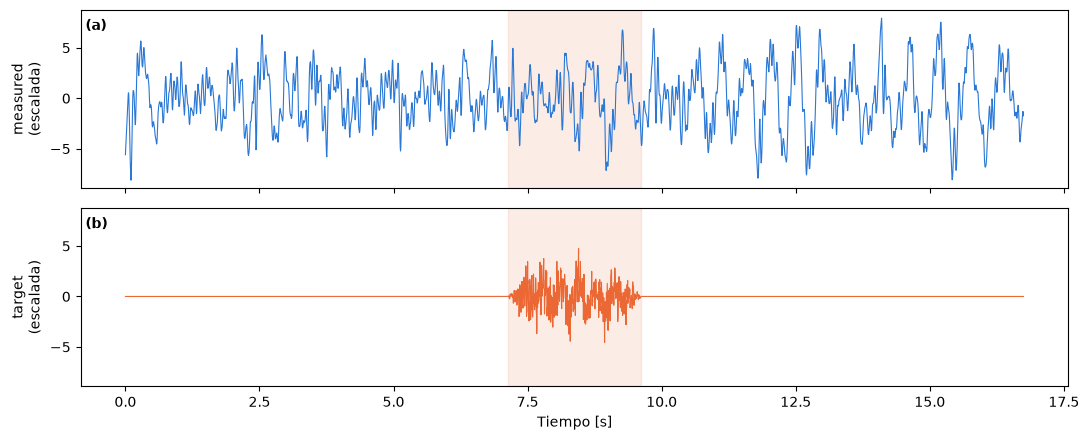

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True, sharey=True)
signals = [X_scaled[i, 0], Y_scaled[i, 0]]
names = ["measured\n(escalada)", "target\n(escalada)"]
colors = ["#2a78d6", "#eb6834"]
for ax, signal, name, color, letter in zip(axes, signals, names, colors, "ab"):
    ax.plot(t[real], signal[real], color=color, lw=0.8)
    ax.axvspan(t_enter, t_leave, color="#eb6834", alpha=0.12)   # time on the bridge
    ax.set_ylabel(name)
    ax.text(0.005, 0.95, f"({letter})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Figura 5.** Señales escaladas del viaje 6 (B3). (a) Aceleración medida. (b) Salida de la red. Los dos paneles tienen la misma escala vertical. La franja naranja marca el tiempo sobre el puente.

Qué se ve: después de escalar, las dos señales tienen un tamaño parecido, aunque antes `measured` era unas 8 veces más grande que `bridge_acc` (0.76 contra 0.09 m/s² de desviación estándar).

## 6. Construir la red

Se usa una **U-Net 1D**: una CNN que recibe una señal y devuelve otra señal del mismo largo. Su nombre viene de su forma de U (Figura 6):

1. **Bajada (izquierda de la U):** la señal se resume y se acorta a la mitad varias veces. Así cada punto de los niveles de abajo "ve" un tramo largo de tiempo.
2. **Subida (derecha de la U):** la señal se alarga al doble varias veces, hasta volver a su largo original.
3. **Conexiones directas (flechas horizontales):** pasan el detalle de cada nivel de la bajada al mismo nivel de la subida, para no perder la forma fina de la señal.

La red tiene que ver un tramo largo alrededor de cada muestra: un cruce puede durar hasta 12 s sobre el puente, y desde el centro del puente la red debe alcanzar la carretera de antes y después para comparar. Por eso la señal se acorta a la mitad 7 veces (8 niveles).

### 6.1 Las piezas de la red

- **Convolución (`Conv1d`):** una ventana de 9 muestras que recorre la señal. En cada posición multiplica las 9 muestras por 9 pesos y las suma (Ec. 2). Los pesos no se fijan a mano: la red los aprende al entrenar. Una capa tiene muchas ventanas distintas (los **canales**), y cada una busca un patrón diferente.

$$y[n] = b + \sum_{k=-4}^{4} w[k]\, x[n+k] \tag{2}$$

- $x$: señal que entra; $y$: señal que sale; $n$: número de la muestra.
- $w[k]$: los 9 pesos de la ventana; $b$: un valor que se suma (sesgo). Los dos se aprenden.
- Si entran varios canales, se hace lo mismo con cada uno y se suman los resultados.

- **ReLU:** deja pasar los valores positivos y cambia los negativos por 0. Sin esta pieza, la red solo podría hacer sumas y multiplicaciones simples.
- **MaxPool (`MaxPool1d(2)`):** acorta la señal a la mitad, quedándose con el mayor de cada par de muestras.
- **Upsample (`Upsample(scale_factor=2)`):** alarga la señal al doble, repitiendo cada muestra.

La pieza básica de la red es un **bloque**: dos convoluciones, cada una seguida de ReLU.

In [15]:
import torch.nn as nn


def conv_block(c_in, c_out):
    # Basic piece of the network: two convolutions, each one followed by ReLU
    return nn.Sequential(
        nn.Conv1d(c_in, c_out, kernel_size=9, padding=4),    # window of 9 samples (Eq. 2)
        nn.ReLU(),
        nn.Conv1d(c_out, c_out, kernel_size=9, padding=4),
        nn.ReLU(),
    )

### 6.2 La red completa

`CHANNELS` dice cuántos canales tiene cada nivel, de arriba hacia abajo. Con 8 niveles la señal se acorta a la mitad 7 veces, así que su largo tiene que poder dividirse por $2^7 = 128$. Por eso, al entrar, la red alarga cada viaje con ceros de 11 000 a 11 008 muestras ($86 \times 128$), y al salir le quita esas 8 muestras.

Una red en PyTorch se escribe como una **clase** con dos partes:

- `__init__`: crea las piezas (los bloques de bajada y de subida).
- `forward`: dice por dónde pasa la señal, en orden.

In [16]:
CHANNELS = [16, 32, 64, 64, 64, 64, 64, 64]   # channels of each level, from top to bottom


class UNet1D(nn.Module):
    def __init__(self, in_channels=2, out_channels=1):
        super().__init__()
        n_levels = len(CHANNELS)

        # Going down: one block per level
        self.down_blocks = nn.ModuleList()
        c_in = in_channels
        for c in CHANNELS:
            self.down_blocks.append(conv_block(c_in, c))
            c_in = c

        # Going up: one block per level (except the bottom one). Each block receives the signal
        # from the level below plus the skip connection from the same level of the way down
        self.up_blocks = nn.ModuleList()
        for level in range(n_levels - 2, -1, -1):    # from the level above the bottom to the top
            self.up_blocks.append(conv_block(CHANNELS[level + 1] + CHANNELS[level], CHANNELS[level]))

        self.pool = nn.MaxPool1d(2)                 # halves the length
        self.upsample = nn.Upsample(scale_factor=2)   # doubles the length
        self.out = nn.Conv1d(CHANNELS[0], out_channels, kernel_size=1)   # final output: 1 channel
        self.multiple = 2 ** (n_levels - 1)         # the length must be a multiple of 128

    def forward(self, x):
        n_samples = x.shape[-1]
        n_extra = (-n_samples) % self.multiple      # zeros needed to reach a multiple of 128
        x = nn.functional.pad(x, (0, n_extra))      # 11000 -> 11008 samples

        # Going down: keep the output of each level for the skip connections
        skips = []
        for level, block in enumerate(self.down_blocks):
            if level > 0:
                x = self.pool(x)
            x = block(x)
            skips.append(x)
        skips.pop()   # the bottom level has no skip connection

        # Going up: double the length, join with the skip connection and apply the block
        for block in self.up_blocks:
            x = self.upsample(x)
            x = torch.cat([x, skips.pop()], dim=1)
            x = block(x)

        x = self.out(x)
        return x[..., :n_samples]   # remove the extra zeros: back to 11000 samples

La Figura 6 muestra la red: en cada nivel, cuántos canales tiene y cuántas muestras tiene la señal.

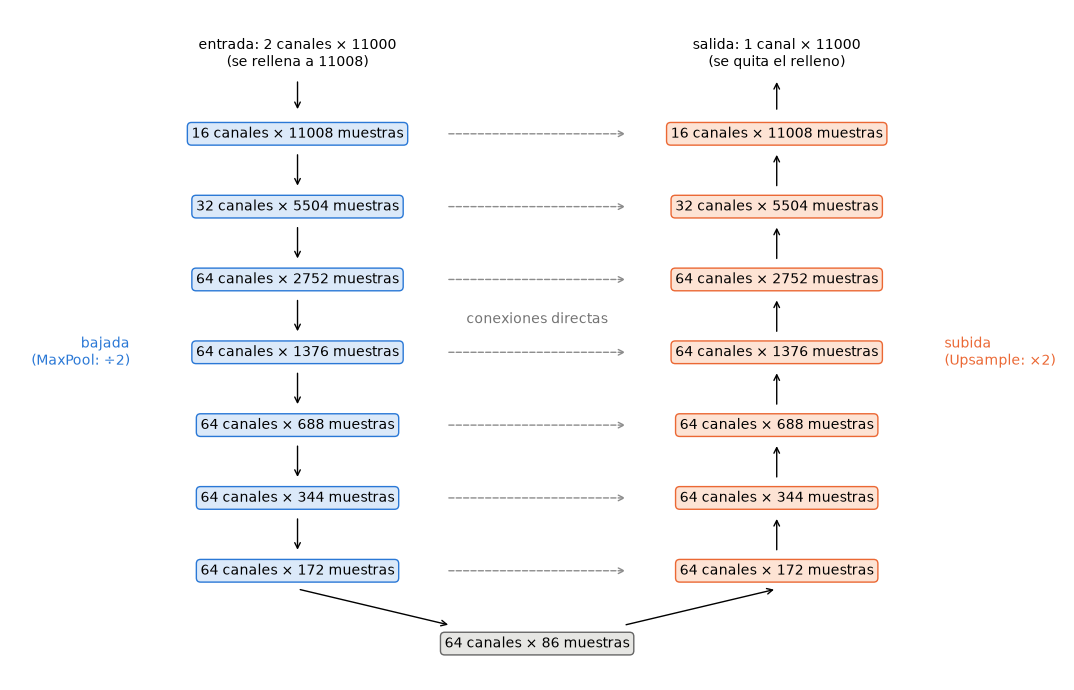

In [17]:
# Diagram of the network, built from CHANNELS
n_levels = len(CHANNELS)
x_down, x_up, x_bottom = 2.5, 7.5, 5.0
box = dict(boxstyle="round,pad=0.3", lw=1)

fig, ax = plt.subplots(figsize=(11, 7))
for level, c in enumerate(CHANNELS):
    text = f"{c} canales × {11008 // 2**level} muestras"
    y = -level
    if level < n_levels - 1:
        ax.text(x_down, y, text, ha="center", va="center", bbox={**box, "fc": "#dbe9f9", "ec": "#2a78d6"})
        ax.text(x_up, y, text, ha="center", va="center", bbox={**box, "fc": "#fde3d4", "ec": "#eb6834"})
        ax.annotate("", (x_up - 1.55, y), (x_down + 1.55, y),
                    arrowprops=dict(arrowstyle="->", ls="--", color="0.55"))    # skip connection
        x_next = x_down if level < n_levels - 2 else x_bottom - 0.9
        x_prev = x_up if level < n_levels - 2 else x_bottom + 0.9
        ax.annotate("", (x_next, y - 0.75), (x_down, y - 0.25), arrowprops=dict(arrowstyle="->"))   # MaxPool
        ax.annotate("", (x_up, y - 0.25), (x_prev, y - 0.75), arrowprops=dict(arrowstyle="->"))     # Upsample
    else:
        ax.text(x_bottom, y, text, ha="center", va="center", bbox={**box, "fc": "#e6e6e3", "ec": "0.4"})

ax.text(x_down, 1.1, "entrada: 2 canales × 11000\n(se rellena a 11008)", ha="center", va="center")
ax.text(x_up, 1.1, "salida: 1 canal × 11000\n(se quita el relleno)", ha="center", va="center")
ax.annotate("", (x_down, 0.3), (x_down, 0.75), arrowprops=dict(arrowstyle="->"))
ax.annotate("", (x_up, 0.75), (x_up, 0.3), arrowprops=dict(arrowstyle="->"))
ax.text(x_down - 1.75, -3, "bajada\n(MaxPool: ÷2)", ha="right", va="center", color="#2a78d6")
ax.text(x_up + 1.75, -3, "subida\n(Upsample: ×2)", ha="left", va="center", color="#eb6834")
ax.text(5, -2.6, "conexiones directas", ha="center", color="0.45")
ax.set_xlim(-0.5, 10.5)
ax.set_ylim(-n_levels + 0.5, 1.7)
ax.axis("off")
plt.tight_layout()
plt.show()

**Figura 6.** Esquema de la U-Net 1D. Cada caja es un bloque (dos convoluciones con ReLU) e indica los canales y el largo de la señal en ese nivel. Azul: bajada; naranja: subida; gris: nivel de abajo. Flechas punteadas: conexiones directas entre la bajada y la subida.

### 6.3 Probar la red

Se crea la red, se cuenta cuántos pesos tiene (sus **parámetros**, lo que aprende al entrenar) y se le pasan 4 viajes de entrenamiento para comprobar que devuelve una señal del largo correcto. La red todavía no está entrenada: sus pesos son números al azar, así que su salida aún no significa nada.

`torch.from_numpy` convierte la tabla de NumPy en un **tensor**, la tabla de PyTorch, y `.to(device)` la pasa a la GPU.

In [18]:
torch.manual_seed(SEED)                     # the initial weights are random: fixed seed
model = UNet1D().to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params:,}")

x = torch.from_numpy(X_train[:4]).to(device)   # 4 crossings
y = model(x)
print("Input: ", tuple(x.shape), "(crossings, channels, samples)")
print("Output:", tuple(y.shape), "(crossings, channels, samples)")

Parameters: 1,041,009


Input:  (4, 2, 11000) (crossings, channels, samples)
Output: (4, 1, 11000) (crossings, channels, samples)


### 6.4 Cuánto tiempo ve la red

Se comprueba cuántas muestras de la entrada usa la red para calcular **una** muestra de la salida, la del centro del viaje. PyTorch puede calcular cuánto cambia esa salida si se mueve un poco cada muestra de la entrada (`backward`, el mismo cálculo que se usa al entrenar). Donde ese cambio es distinto de 0, la red "ve" esa muestra.

In [19]:
x = torch.randn(1, 2, n_samples, device=device, requires_grad=True)   # a random input
y = model(x)
center = n_samples // 2
y[0, 0, center].backward()                  # how the center output depends on each input sample

seen = torch.nonzero(x.grad[0].abs().sum(dim=0) > 0).flatten()   # input samples the network uses
before = (center - seen.min().item()) / FS
after = (seen.max().item() - center) / FS
print(f"The network sees {before:.1f} s before and {after:.1f} s after each sample")

The network sees 15.3 s before and 15.3 s after each sample


La red ve unos 15 s antes y después de cada muestra. El cruce más largo dura 11.9 s sobre el puente, así que desde el centro del puente la red alcanza al menos 9 s de carretera a cada lado (la carretera de antes y después dura de 4 a 20 s, según la velocidad).

## 7. Entrenar la red

Entrenar es repetir muchas veces tres pasos:

1. La red recibe un grupo de viajes (un **lote**) y calcula su salida.
2. Se mide el **error** entre su salida y el target.
3. Se corrigen un poco todos los pesos de la red, en la dirección que baja ese error.

Una **época** es una pasada por todos los viajes de entrenamiento. Al final de cada época se mide el error en los viajes de validación, que la red no usa para aprender. Así se ve si la red aprende algo que sirve en viajes nuevos o si solo memoriza los de entrenamiento.

### 7.1 La función de error

El error se calcula **solo sobre las muestras del puente** (donde `bridge_mask` = 1). Fuera del puente el target vale 0 y no interesa.

$$E = \frac{1}{N_p} \sum_{n \,\in\, \text{puente}} \left( \hat{y}[n] - y[n] \right)^2 \tag{3}$$

- $\hat{y}[n]$: salida de la red en la muestra $n$ (escalada).
- $y[n]$: target en la muestra $n$ (escalado).
- $N_p$: número de muestras sobre el puente.

En palabras: el promedio de las diferencias al cuadrado sobre el puente (error cuadrático medio). Como el target está escalado (sección 5), su desviación estándar sobre el puente es 1. Por eso, **si la red devolviera siempre 0, el error sería cerca de 1**: es la referencia para saber si la red aprendió algo.

In [20]:
def bridge_loss(prediction, target, mask):
    # Mean squared error using only the samples on the bridge (mask = 1) (Eq. 3)
    squared_error = (prediction - target) ** 2
    return (squared_error * mask).sum() / mask.sum()

### 7.2 Entrenamiento

**Tabla 4.** Configuración del entrenamiento.

| Parámetro | Valor | Qué es |
|---|---|---|
| `EPOCHS` | 100 | pasadas por todos los viajes de entrenamiento |
| `BATCH_SIZE` | 8 | viajes por lote |
| `LEARNING_RATE` | 0.0003 | tamaño de cada corrección de los pesos |
| Optimizador | Adam | método que decide cómo corregir cada peso |

Se guarda el error de cada época y los pesos de la época con **menor error de validación**; al final, la red se queda con esos pesos. Tarda unos 4 minutos en la GPU.

In [21]:
import copy

EPOCHS = 100
BATCH_SIZE = 8
LEARNING_RATE = 3e-4

# Data as tensors on the GPU
x_train = torch.from_numpy(X_train).to(device)
y_train = torch.from_numpy(Y_train).to(device)
x_val = torch.from_numpy(X_val).to(device)
y_val = torch.from_numpy(Y_val).to(device)

torch.manual_seed(SEED)
model = UNet1D().to(device)   # a new network, not trained yet
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_history = []   # training error of each epoch
val_history = []     # validation error of each epoch
best_val = float("inf")

for epoch in range(EPOCHS):
    # 1) Training: the training crossings in random order, in batches of BATCH_SIZE
    model.train()
    order = torch.randperm(len(x_train))
    epoch_error = 0
    for start in range(0, len(x_train), BATCH_SIZE):
        batch = order[start:start + BATCH_SIZE]
        x, y = x_train[batch], y_train[batch]
        error = bridge_loss(model(x), y, x[:, 1:2])   # channel 1 of the input = bridge_mask
        optimizer.zero_grad()   # clear the corrections of the previous batch
        error.backward()        # how to change each weight to reduce the error
        optimizer.step()        # change the weights
        epoch_error += error.item() * len(batch)
    train_history.append(epoch_error / len(x_train))

    # 2) Validation: error on crossings the network does not learn from
    model.eval()
    with torch.no_grad():
        epoch_error = 0
        for start in range(0, len(x_val), BATCH_SIZE):
            x, y = x_val[start:start + BATCH_SIZE], y_val[start:start + BATCH_SIZE]
            epoch_error += bridge_loss(model(x), y, x[:, 1:2]).item() * len(x)
    val_history.append(epoch_error / len(x_val))

    # 3) Keep the weights of the epoch with the lowest validation error
    if val_history[-1] < best_val:
        best_val = val_history[-1]
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:3d}: training error {train_history[-1]:.3f}, validation error {val_history[-1]:.3f}")

model.load_state_dict(best_weights)
print(f"Lowest validation error: {best_val:.3f} (epoch {best_epoch})")

Epoch  10: training error 0.984, validation error 1.041


Epoch  20: training error 0.971, validation error 1.042


Epoch  30: training error 0.992, validation error 1.043


Epoch  40: training error 0.990, validation error 1.043


Epoch  50: training error 0.961, validation error 1.050


Epoch  60: training error 0.959, validation error 1.074


Epoch  70: training error 0.937, validation error 1.080


Epoch  80: training error 0.901, validation error 1.108


Epoch  90: training error 0.854, validation error 1.129


Epoch 100: training error 0.823, validation error 1.142
Lowest validation error: 1.041 (epoch 9)


Error if the network returns 0: training 1.000, validation 1.100


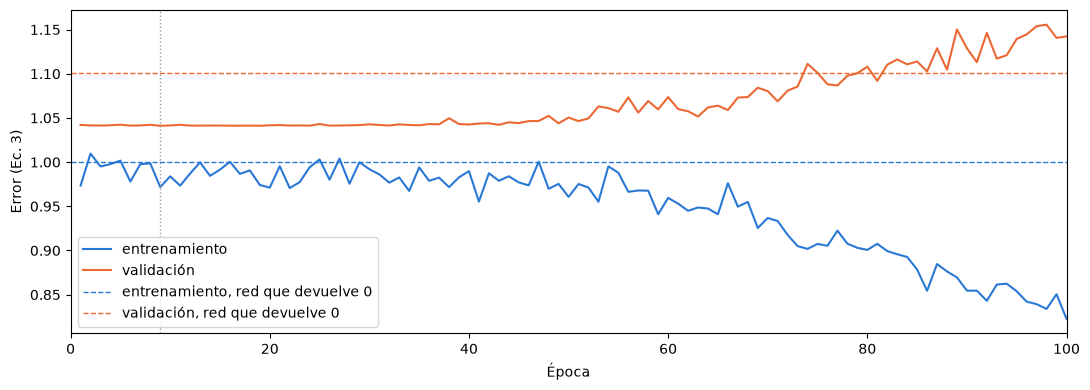

In [22]:
# Reference: error of a network that always returns 0
zero_train = bridge_loss(torch.zeros_like(y_train), y_train, x_train[:, 1:2]).item()
zero_val = bridge_loss(torch.zeros_like(y_val), y_val, x_val[:, 1:2]).item()
print(f"Error if the network returns 0: training {zero_train:.3f}, validation {zero_val:.3f}")

epochs = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(epochs, train_history, color="#2a78d6", label="entrenamiento")
ax.plot(epochs, val_history, color="#eb6834", label="validación")
ax.axhline(zero_train, color="#2a78d6", ls="--", lw=1, label="entrenamiento, red que devuelve 0")
ax.axhline(zero_val, color="#eb6834", ls="--", lw=1, label="validación, red que devuelve 0")
ax.axvline(best_epoch, color="0.6", ls=":", lw=1)
ax.set_xlabel("Época")
ax.set_ylabel("Error (Ec. 3)")
ax.set_xlim(0, EPOCHS)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Figura 7.** Error de entrenamiento (azul) y de validación (naranja) en cada época. Líneas discontinuas: error que tendría una red que devuelve siempre 0, en cada grupo. Línea punteada: época con el menor error de validación.

Qué se ve:

- **Validación (naranja):** desde la primera época el error queda en 1.04, un 5 % por debajo del de una red que devuelve 0 (1.10). La red capta solo una parte pequeña del target, y eso no mejora con más épocas.
- **Entrenamiento (azul):** desde la época 40, más o menos, el error baja hasta 0.77, mientras el de validación sube por encima de 1.10. La red **memoriza** los viajes de entrenamiento (sobreajuste): lo que aprende no sirve en viajes nuevos.
- La red se queda con los pesos de la época con menor error de validación. Los números cambian un poco en cada ejecución, porque la GPU no hace las sumas siempre en el mismo orden.

Posible explicación, que se comprueba en la sección 8: sobre el puente, la parte del puente en la señal del teléfono es mucho más débil que la de la rugosidad del puente (entre 9 y 27 dB menos cerca de f1, según el puente), y esa rugosidad no se conoce. Si la red no puede saber la amplitud y la fase exactas de la oscilación del puente en cada viaje, el error de la Ec. 3, que compara muestra por muestra, es menor si devuelve casi 0.

## 8. Evaluar en los viajes de prueba

Se usa la red entrenada en la sección 7 con los 150 viajes de prueba, que no se usaron ni para entrenar ni para elegir los pesos. Se evalúa en tres pasos:

1. El error de la Ec. 3 en cada puente, comparado con el de una red que devuelve 0.
2. La salida de la red en el tiempo, en un viaje.
3. El espectro de la salida comparado con el de `bridge_acc`, **en cada modo del puente** (Tabla 3).

### 8.1 Error en cada puente

La salida de la red se multiplica por `scale_target` para volver a m/s². `torch.no_grad()` le dice a PyTorch que no prepare correcciones de los pesos, porque aquí la red no aprende.

In [23]:
x_test = torch.from_numpy(X_test).to(device)

model.eval()
predictions = []
with torch.no_grad():
    for start in range(0, len(x_test), BATCH_SIZE):
        predictions.append(model(x_test[start:start + BATCH_SIZE]).cpu().numpy())

pred_test = np.concatenate(predictions)[:, 0, :] * scale_target   # network output [m/s^2]
true_test = Y_test[:, 0, :] * scale_target                        # target [m/s^2]
on_test = X_test[:, 1, :] == 1                                    # samples on the bridge
names_test = bridge_name[test_idx]                                # bridge of each test crossing

**Tabla 5.** Error sobre el puente en los viajes de prueba (Ec. 3, escalado) y tamaño de la salida de la red comparado con el del target (cociente de desviaciones estándar).

In [24]:
print("Bridge  error network  error if 0  size output / size target")
for name in np.unique(bridge_name):
    rows = names_test == name
    on = on_test[rows]                                   # samples on the bridge of these crossings
    pred_on = pred_test[rows][on]
    true_on = true_test[rows][on]
    error_network = np.mean((pred_on - true_on) ** 2) / scale_target**2
    error_zero = np.mean(true_on ** 2) / scale_target**2
    size = pred_on.std() / true_on.std()
    print(f"{name:6}  {error_network:13.3f}  {error_zero:10.3f}  {size:26.3f}")

Bridge  error network  error if 0  size output / size target
B1              0.516       0.515                       0.055
B2              1.101       1.100                       0.039
B3              0.512       0.511                       0.050
B4              1.002       1.003                       0.039
B5              1.519       1.529                       0.034


En los cinco puentes, el error de la red es prácticamente igual al de una red que devuelve 0 (diferencias de 0.01 o menos). La salida de la red mide entre el 3 y el 6 % del target: la red devuelve casi 0.

### 8.2 Un viaje en el tiempo

Se grafica la salida de la red y el target sobre el puente, en el primer viaje de prueba de B3 (Figura 8).

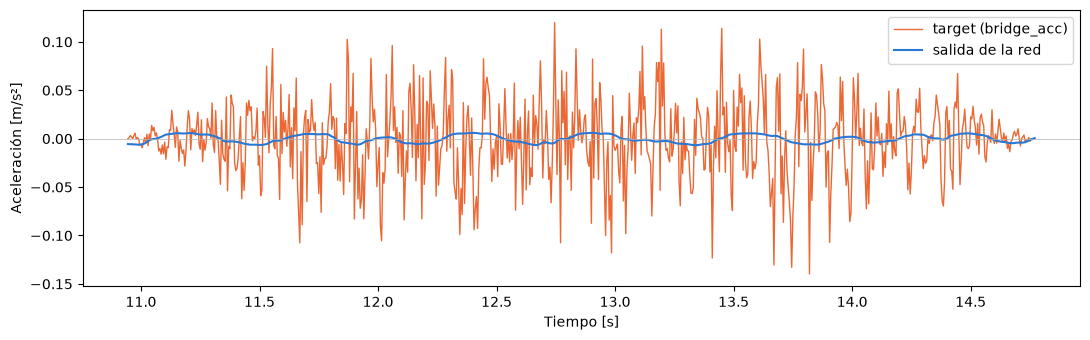

In [25]:
j = np.where(names_test == "B3")[0][0]   # first test crossing of B3
on = on_test[j]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(t[on], true_test[j][on], color="#eb6834", lw=1, label="target (bridge_acc)")
ax.plot(t[on], pred_test[j][on], color="#2a78d6", lw=1.5, label="salida de la red")
ax.axhline(0, color="0.7", lw=0.5)
ax.set_xlabel("Tiempo [s]")
ax.set_ylabel("Aceleración [m/s²]")
ax.legend()
plt.tight_layout()
plt.show()

**Figura 8.** Target (naranja) y salida de la red (azul) sobre el puente, en el primer viaje de prueba de B3 (f1 = 3.0 Hz).

### 8.3 Espectro en cada modo

El **espectro de potencia** dice cuánta energía tiene una señal en cada frecuencia. Se calcula para el tramo sobre el puente de cada viaje y se promedia entre los 30 viajes de prueba de cada puente, para que se vea más limpio:

$$S(f) = \frac{\left| \mathrm{FFT}\{ w \cdot x \}(f) \right|^2}{\sum w^2} \tag{4}$$

- $x$: la señal sobre el puente.
- $w$: ventana de Hann, que lleva la señal suavemente a 0 en los extremos para que el corte no cree frecuencias falsas.
- FFT: transformada de Fourier, que pasa la señal del tiempo a las frecuencias.
- $S(f)$: potencia de la señal en la frecuencia $f$.

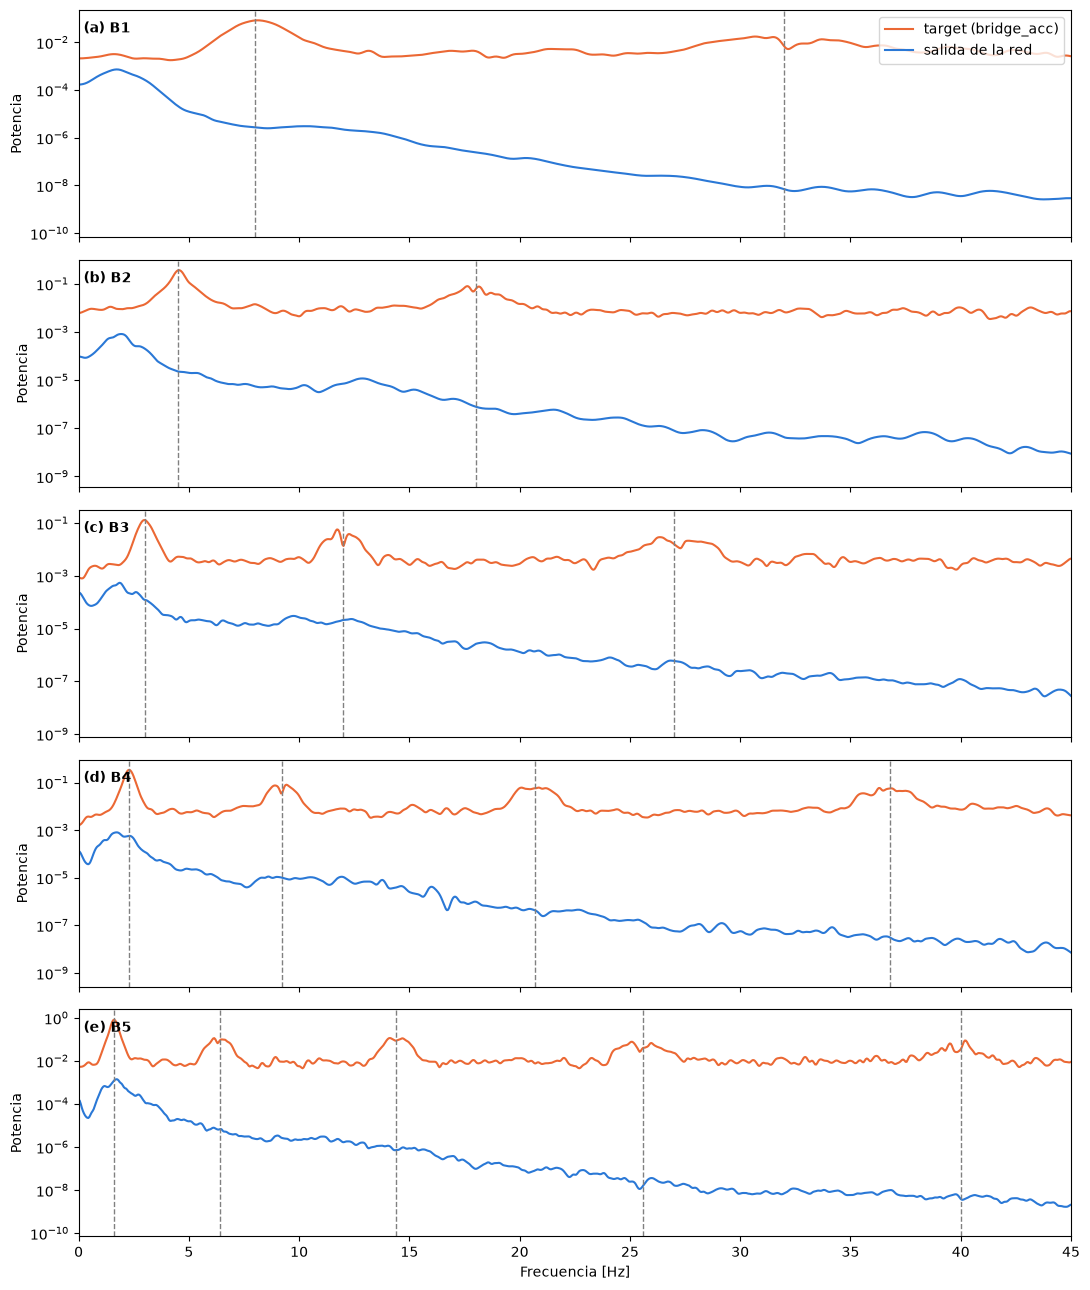

In [26]:
N_FFT = 4096
freqs = np.fft.rfftfreq(N_FFT, 1 / FS)   # frequency of each point of the spectrum [Hz]


def power_spectrum(signal):
    # Power of each frequency of the signal (Eq. 4)
    window = np.hanning(len(signal))
    return np.abs(np.fft.rfft(signal * window, N_FFT)) ** 2 / np.sum(window**2)


# Spectrum of the target and of the output, averaged over the test crossings of each bridge
spec_true = {}
spec_pred = {}
for name in np.unique(bridge_name):
    rows = np.where(names_test == name)[0]
    spec_true[name] = np.mean([power_spectrum(true_test[k][on_test[k]]) for k in rows], axis=0)
    spec_pred[name] = np.mean([power_spectrum(pred_test[k][on_test[k]]) for k in rows], axis=0)

fig, axes = plt.subplots(5, 1, figsize=(11, 13), sharex=True)
for ax, name, letter in zip(axes, np.unique(bridge_name), "abcde"):
    ax.semilogy(freqs, spec_true[name], color="#eb6834", label="target (bridge_acc)")
    ax.semilogy(freqs, spec_pred[name], color="#2a78d6", label="salida de la red")
    modes = bridge_freqs[bridge_name == name][0]
    for fn in modes[~np.isnan(modes)]:
        ax.axvline(fn, color="0.5", ls="--", lw=1)
    ax.set_ylabel("Potencia")
    ax.text(0.005, 0.95, f"({letter}) {name}", transform=ax.transAxes, va="top", fontweight="bold")
axes[0].legend(loc="upper right")
axes[-1].set_xlim(0, 45)
axes[-1].set_xlabel("Frecuencia [Hz]")
plt.tight_layout()
plt.show()

**Figura 9.** Espectro de potencia sobre el puente, promediado en los 30 viajes de prueba de cada puente: target (naranja) y salida de la red (azul). (a)–(e) Puentes B1 a B5. Líneas discontinuas: frecuencias de los modos de cada puente (Tabla 3). Eje vertical en escala logarítmica.

**Tabla 6.** Para cada modo: cuánto de la amplitud del target aparece en la salida de la red (raíz del cociente de los picos de potencia, buscando el pico dentro de ±10 % de la frecuencia del modo). También la frecuencia del pico más alto de la salida de la red.

In [27]:
for name in np.unique(bridge_name):
    band = (freqs > 0.5) & (freqs < 45)
    f_peak = freqs[band][np.argmax(spec_pred[name][band])]   # highest peak of the output
    print(f"{name}: highest peak of the output at {f_peak:.1f} Hz")
    modes = bridge_freqs[bridge_name == name][0]
    for n, fn in enumerate(modes[~np.isnan(modes)], start=1):
        near = (freqs > 0.9 * fn) & (freqs < 1.1 * fn)          # +-10 % around the mode
        captured = np.sqrt(spec_pred[name][near].max() / spec_true[name][near].max())
        print(f"   mode {n} ({fn:4.1f} Hz): {100 * captured:5.1f} % of the amplitude")

B1: highest peak of the output at 1.7 Hz
   mode 1 ( 8.0 Hz):   0.6 % of the amplitude
   mode 2 (32.0 Hz):   0.1 % of the amplitude
B2: highest peak of the output at 2.0 Hz
   mode 1 ( 4.5 Hz):   0.9 % of the amplitude
   mode 2 (18.0 Hz):   0.5 % of the amplitude
B3: highest peak of the output at 1.9 Hz
   mode 1 ( 3.0 Hz):   3.9 % of the amplitude
   mode 2 (12.0 Hz):   2.0 % of the amplitude
   mode 3 (27.0 Hz):   0.5 % of the amplitude
B4: highest peak of the output at 1.7 Hz
   mode 1 ( 2.3 Hz):   4.1 % of the amplitude
   mode 2 ( 9.2 Hz):   1.2 % of the amplitude
   mode 3 (20.7 Hz):   0.3 % of the amplitude
   mode 4 (36.8 Hz):   0.1 % of the amplitude
B5: highest peak of the output at 1.7 Hz
   mode 1 ( 1.6 Hz):   4.1 % of the amplitude
   mode 2 ( 6.4 Hz):   0.8 % of the amplitude
   mode 3 (14.4 Hz):   0.4 % of the amplitude
   mode 4 (25.6 Hz):   0.1 % of the amplitude
   mode 5 (40.0 Hz):   0.0 % of the amplitude


Qué se ve:

- **Figura 8:** la salida de la red es una oscilación pequeña y suave, de un ciclo cada ~0.5 s (unos 2 Hz). No sigue al target.
- **Figura 9 y Tabla 6:** en los cinco puentes, el pico más alto de la salida está entre 1.7 y 2.0 Hz, en el mismo lugar sea cual sea el puente. Ese es el rango de la frecuencia del cuerpo del carro (1 a 2 Hz), no el del puente. La salida no tiene picos en las frecuencias de los modos de ningún puente.
- En el modo 1, la salida tiene como mucho el 4 % de la amplitud del target (B3, B4 y B5). En los modos altos, el 2 % o menos.

**Resultado de la primera corrida:** con la versión A (`measured` + máscara), el target `bridge_acc` completo y un error que compara muestra por muestra, la red no obtiene ningún modo del puente. Esto es consistente con la posible explicación de la sección 7: lo que menos error da es devolver casi 0.